# [과제] CNN 전이학습(Transfer Learning) 수행과제

## 1. 과제 개요
사전 학습된(Pre-trained) CNN 모델을 활용하여 새로운 이미지 분류(Image Classification) 문제를 해결
데이터셋의 특성과 사전 학습 모델 간의 유사도를 고려하여 적절한 미세조정(Fine-Tuning) 전략 수립 및 구현

## 2.과제 수행 단계 및 세부 문항

### [1단계] 데이터셋 선정 및 다운로드 (Dataset Preparation)
자신이 관심 있거나 해결하고 싶은 도메인의 이미지 분류용 데이터셋을 직접 검색하고 다운로드합니다

## Q1-1. 사용할 데이터셋의 이름, 출처(링크 등), 그리고 데이터셋을 선정한 이유를 설명하시오

## 사용하는 데이터셋의 이름 
### 한국인 감정인식을 위한 복합 영상

### 출처 : AI Hub (https://www.aihub.or.kr/aihubdata/data/view.do?pageIndex=43&currMenu=115&topMenu=100&srchOptnCnd=OPTNCND001&srchDetailCnd=DETAILCND001&srchOrder=ORDER001&srchPagePer=20&aihubDataSe=data&dataSetSn=82)

### 데이터 셋의 선정 이유
글을 읽거나 쓰는 문맥적 일을 할때와 같은 서사 활동시에 사람의 숨은 표정이 있을 것이라고 판단된다.

특히 뉴스를 보거나, 누군가에게 메세지를 보내거나 할 때, 무의식적으로 감정이 얼굴에 올라온다.

그렇게 뉴스나 메세지를 보낼 때, 그에 대한 감정을 표현방식을 활용하여 다른 무언가에 활용하려고 한다.

## Q1-2. 데이터셋의 총 이미지 수, 클래스(Class) 개수, 각 클래스별 데이터 분포(균등,편향)를 요약하시오.

### 데이터셋의 총 이미지 수
488,776 장의 이미지

### 클래스 개수
7개 (기쁨, 당황, 분노, 불안, 상처, 슬픔, 중립)

### 각 클래스별 데이터 분포
| 클래스 명 | 이미지 수 | 분포 |
| --- | --- | --- |
| 기쁨 | 70,735 | 14.47% |
| 당황 | 70,457 | 14.41% |
| 분노 | 68,835 | 14.08% |
| 불안 | 69,965 | 14.31% |
| 상처 | 70,103 | 14.34% |
| 슬픔 | 70,508 | 14.42% |
| 중립 | 68,173 | 13.94% |
| --- | --- | --- |
| 합계 | 488,776 | --- |

## 실 사용 데이터 수

### 데이터셋의 총 이미지 수
488,776 장의 이미지

### 클래스 개수
7개 (기쁨, 당황, 분노, 불안, 상처, 슬픔, 중립)

### 각 클래스별 데이터 분포
| 클래스 명 | 이미지 수 | 분포 |
| --- | --- | --- |
| 기쁨 | 7,499 | 14.43% |
| 당황 | 7,454 | 14.30% |
| 분노 | 7,461 | 14.30% |
| 불안 | 7,407 | 14.20% |
| 상처 | 7,423 | 14.23% |
| 슬픔 | 7,479 | 14.34% |
| 중립 | 7,403 | 14.20% |
| --- | --- | --- |
| 합계 | 52,126 | --- |

[2단계] 사전 학습 모델(Pre-trained Model) 탐색 및 선정 (Model Exploration)
다양한 공개 사전 학습 모델을 조사하고, 본 과제의 데이터셋에 가장 적합한 모델을 탐색합니다

Q2-1. 컴퓨터 비전 분야에서 널리 쓰이는 사전 학습 모델 3가지 이상을 조사하고 각각의 특징(구조, 장점
등)을 비교하시오. (예: ResNet, VGG, EfficientNet, MobileNet 등)

![모바일을 위한 모델들](./note_images/Gemini_Generated_Image_5kcisz5kcisz5kci.png "모바일 CNN을 위한 모델들")

1. MobileNet 시리즈 (Google)
MobileNetV1: Howard et al., 2017 — "MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications" (arXiv:1704.04861)

MobileNetV2: Sandler et al., 2018 — "MobileNetV2: Inverted Residuals and Linear Bottlenecks" (CVPR 2018)

MobileNetV3: Howard et al., 2019 — "Searching for MobileNetV3" (ICCV 2019)

2. EfficientNet 시리즈 (Google Research)
EfficientNetV1: Tan & Le, 2019 — "EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks" (ICML 2019)

EfficientNetV2: Tan & Le, 2021 — "EfficientNetV2: Smaller Models and Faster Training" (ICML 2021)

3. ShuffleNet 시리즈 (Megvii / Face++)
ShuffleNetV1: Zhang et al., 2018 — "ShuffleNet: An Extremely Efficient Convolutional Neural Network for Mobile Devices" (CVPR 2018)

ShuffleNetV2: Ma et al., 2018 — "ShuffleNet V2: Practical Guidelines for Efficient CNN Architecture Design" (ECCV 2018)

4. SqueezeNet (UC Berkeley & Stanford)
SqueezeNet: Iandola et al., 2016 — "SqueezeNet: AlexNet-level accuracy with 50x fewer parameters and <0.5MB model size" (arXiv:1602.07360)

5. GhostNet (Huawei Noah's Ark Lab)
GhostNet: Han et al., 2020 — "GhostNet: More Features from Cheap Operations" (CVPR 2020)

💡 참고 (벤치마크 기준 데이터셋):
제시된 정확도 및 연산 시간 비교 수치는 컴퓨터 비전의 대표 벤치마크 데이터셋인 ImageNet (ILSVRC classification) 검증 데이터셋 기준 Top-1 Accuracy이며, 추론 시간은 주로 모바일 CPU/GPU(예: Pixel / iPhone / ARM Cortex) 환경에서 TFLite 또는 CoreML을 적용했을 때의 공개 측정 결과를 기반으로 측정됩니다.


탐색 대상: MobileNetV3(Large), GhostNet, EfficientNet-B#

1. MobileNetV3(Large)

1) 구조

하드웨어 인식 신경망 탐색기법과 네트워크 구조 최적화를 바탕으로 설계되었으며, 효율적인 역잔차구조에 어텐션 메커니즘인 SE(Squeeze-and-Excitation) 모듈과 하드 스위시 활성화 함수를 결합한 형태입니다.

2) 장점

모바일 CPU 환경에서 연산 속도와 정확도를 극대화하여 이전 버전 대비 적은 연산량으로도 우수한 이미지 분류 성능을 제공합니다.

3) 깊이 및 파라미터:

    깊이: 약 15~17개의 주요 병목(Bottleneck) 블록 구조 (전체 약 50여 개 레이어)

    파라미터 수: 약 5.4M (540만 개)



2. GhostNet

1) 구조

일반적인 합성곱 연산으로 최소한의 기본 특징 맵만 추출한 뒤, 연산 비용이 매우 적은 선형 연산을 통해 추가적인 유령 채널들을 복제·생성하여 최종 특징 맵을 구성합니다.

2) 장점

모델의 파라미터 수와 연산량(FLOPs)을 획기적으로 줄이면서도 정보 손실을 최소화하여, 자원이 극도로 제한된 모바일 환경에서 높은 효율과 정확도를 발휘합니다.

3) 깊이 및 파라미터:

    깊이: 약 10~14개의 주요 Ghost 모듈 스테이지

    파라미터 수: 약 3.9M ~ 5.2M (1.0x 스케일 기준 약 520만 개)


3. EfficientNet-B# (B0 ~ B7)

1) 구조

모바일 역잔차 블록을 기본 뼈프로 삼고, 네트워크의 깊이, 너비, 해상도의 세 가지 차원을 '복합 스케일링' 규칙에 따라 체계적으로 균형 있게 확장하는 구조입니다.

2) 장점

유사한 성능을 내는 기존 대형 모델들에 비해 파라미터 수와 연산량을 대폭 절감하여, 모바일 및 엣지 디바이스부터 클라우드 환경까지 뛰어난 정확도와 자원 효율성을 동시에 제공합니다.

3) 깊이 및 파라미터 (버전별 확장):

    EfficientNet-B0 (기준 모델): 7개의 스테이지 (총 16개의 MBConv 블록), 파라미터 약 5.3M (530만 개)

    EfficientNet-B1 ~ B7: 스케일링 계수($\phi$)에 따라 깊이와 너비가 체계적으로 커지며, 상위 모델로 갈수록 파라미터가 증가합니다 (예: B3 약 12M, B4 약 19M, B7 최대 약 66M개).

Q2-2. 본 과제의 데이터셋에 가장 적합하다고 판단한 사전 학습 모델을 최종 선정하고, 그 이유를
서술하시오.

목표에 맞는 모델을 찾기 위해 다음과 같은 조건을 두고 널리 쓰이는 모델을 검색
- 카메라로 표정을 취득하기 좋은 환경 = 모바일
- 머무는 시간이 짧은 활동 - 즉각적인 반응

[3단계] 데이터셋 크기와 유사도에 따른 미세조정(Fine-Tuning) 전략 수립 (Strategy & Implementation)
사전 학습 모델을 적용할 때, "데이터셋의 크기"와 "사전 학습된 데이터셋과의 유사도"에 따라 4가지 전략
중 하나를 선택해야 합니다. 현재 본인의 과제 상황이 어디에 해당하는지 분석하고 전략을 결정하세요.

Q3-1. 현재 본인의 데이터셋은 위 4가지 상황 중 어디에 해당하는지 분석하고, 결정한 미세조정
방식(전체 동결, 일부 동결 후 미세조정, 전체 재학습 등)을 간단히 기술하시오.

데이터가 많은 편이라고 생각이 들고, 유사도는 낮을 것으로 예상되어 전체 새로 학습을 하는 것으로 목표로 함

Q3-2. 선택한 전략에 맞춰 PyTorch 또는 TensorFlow/Keras 코드를 작성하고, 모델의 학습(Training)
과정을 수행하시오. (코드 및 학습 로그 첨부)

In [4]:
# zip 파일들로 데이터 프레임 만들기
import os
import zipfile
import pandas as pd
from PIL import Image
import io

def create_image_dataframe(zip_dir):
    samples = []
    zip_files = sorted([f for f in os.listdir(zip_dir) if f.endswith('.zip')])
    
    for zip_filename in zip_files:
        zip_path = os.path.join(zip_dir, zip_filename)
        class_name = os.path.splitext(zip_filename)[0]
        
        with zipfile.ZipFile(zip_path, 'r') as zf:
            for file_info in zf.infolist():
                if file_info.is_dir():
                    continue
                # macOS 메타파일 등 불필요한 파일 필터링
                if file_info.filename.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')) and not '__MACOSX' in file_info.filename:
                    # samples.append({
                    #     'zip_path': zip_path,
                    #     'file_name': file_info.filename,
                    #     'class_name': class_name
                    # })
                    try:
                        with zf.open(file_info.filename) as f:
                            img = Image.open(io.BytesIO(f.read()))
                            img.verify() # 이미지 무결성 검증
                        samples.append({
                            'zip_path': zip_path,
                            'file_name': file_info.filename,
                            'class_name': class_name
                        })
                    except Exception:
                        print(f"제외된 깨진 파일: {file_info.filename}")
                    
    df = pd.DataFrame(samples)
    
    # 클래스 이름을 숫자로 매핑하기 위한 인덱스 생성
    classes = sorted(df['class_name'].unique().tolist())
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    df['label'] = df['class_name'].map(class_to_idx)
    
    return df, classes, class_to_idx

# 실행
zip_dir = './dataset/emotion_data/Validation'
df, classes, class_to_idx = create_image_dataframe(zip_dir)
print(f"인식된 클래스: {classes}")
print(df.head())

인식된 클래스: ['ANGER', 'ANXIETY', 'EMBARRASS', 'HAPPINESS', 'HURT', 'NEUTRAL', 'SADNESS']
                                      zip_path  \
0  ./dataset/emotion_data/Validation/ANGER.zip   
1  ./dataset/emotion_data/Validation/ANGER.zip   
2  ./dataset/emotion_data/Validation/ANGER.zip   
3  ./dataset/emotion_data/Validation/ANGER.zip   
4  ./dataset/emotion_data/Validation/ANGER.zip   

                                           file_name class_name  label  
0  006b56dc2f8cda2361e1b01b2496d6f352dd5b1790f0a9...      ANGER      0  
1  006b56dc2f8cda2361e1b01b2496d6f352dd5b1790f0a9...      ANGER      0  
2  006b56dc2f8cda2361e1b01b2496d6f352dd5b1790f0a9...      ANGER      0  
3  006b56dc2f8cda2361e1b01b2496d6f352dd5b1790f0a9...      ANGER      0  
4  006b56dc2f8cda2361e1b01b2496d6f352dd5b1790f0a9...      ANGER      0  


In [5]:
# 훈련용, 테스트용으로 쪼개기
from sklearn.model_selection import train_test_split

# 80%는 학습용, 20%는 테스트용으로 분할 (클래스 비율 유지)
train_df, test_df = train_test_split(
    df, 
    test_size=0.2, 
    random_state=42, 
    stratify=df['label']
)

print(f"Train 샘플 수: {len(train_df)}, Test 샘플 수: {len(test_df)}")

Train 샘플 수: 41700, Test 샘플 수: 10426


In [6]:
import io
from PIL import Image
import torch
from torch.utils.data import Dataset

# EmotionDataset 클래스 정의
class EmotionDataset(Dataset):
    def __init__(self, df, transform):
        # 인덱스 재정렬 (iloc 접근을 위해)
        self.df = df.reset_index(drop=True)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        zip_path = row['zip_path']
        file_name = row['file_name']
        label = row['label']
        try:
            # ZIP 파일 안에서 이미지 바이트 읽기
            with zipfile.ZipFile(zip_path, 'r') as zf:
                with zf.open(file_name) as f:
                    image_bytes = f.read()
                    image = Image.open(io.BytesIO(image_bytes)).convert('RGB')
                    
            if self.transform:
                image = self.transform(image)
            return image, torch.tensor(label, dtype=torch.long)
            
        except Exception as e:
            # 에러가 난 파일의 경로를 출력하고, 학습이 멈추지 않도록 조치
            print(f"\n[경고] 손상된 이미지 파일 무시됨: {file_name} (에러: {e})")
            
            # 대안 1: 비어있는 더미 이미지(검은 화면 등)를 리턴하여 배치 깨짐 방지
            # (원하는 크기로 생성, 예: 224x224)
            dummy_image = Image.new('RGB', (224, 224), color=0)
            if self.transform:
                dummy_image = self.transform(dummy_image)
            return dummy_image, torch.tensor(label, dtype=torch.long)

In [7]:
from torchvision import transforms, models
from torch.utils.data import DataLoader

# 사전 학습 모델 준비
weights = models.MobileNet_V3_Large_Weights.DEFAULT
transform = weights.transforms()

# 1. Dataset 인스턴스 생성
train_dataset = EmotionDataset(train_df, transform=transform)
test_dataset = EmotionDataset(test_df, transform=transform)

# 2. DataLoader 변환
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train DataLoader 배치 개수: {len(train_loader)}")
print(f"Test DataLoader 배치 개수: {len(test_loader)}")

Train DataLoader 배치 개수: 1304
Test DataLoader 배치 개수: 326


In [ ]:
from sympy import true
import torch.nn as nn

# model 준비
model = models.mobilenet_v3_large(weights=weights)
# model 구조 확인
# print(model)

if 0: # 학습을 위한 영역

    # 마지막 분류층만 학습하도록 변경
    print(model.classifier)
    # Sequential(
    #   (0): Linear(in_features=960, out_features=1280, bias=True)
    #   (1): Hardswish()
    #   (2): Dropout(p=0.2, inplace=True)
    #   (3): Linear(in_features=1280, out_features=1000, bias=True)
    # )

    print()
    model.classifier = nn.Sequential(
        nn.Linear(in_features=960, out_features=1280, bias=True),
        nn.Hardswish(),
        nn.Dropout(p=0.2, inplace=True),
        nn.Linear(in_features=1280, out_features=len(df['label'].unique()), bias=True)
    )
    print(model.classifier)
    # Sequential(
    #   (0): Linear(in_features=960, out_features=1280, bias=True)
    #   (1): Hardswish()
    #   (2): Dropout(p=0.2, inplace=True)
    #   (3): Linear(in_features=1280, out_features=7, bias=True)
    # )

    # 모델 가중치 학습가능한 가중치 변경
    # 마지막 FC 층만 학습하도록 변경
    for param in model.parameters():
        param.requires_grad = False

    for param in model.classifier[3].parameters():
        param.requires_grad = True

    # 업데이트 가능 parameter 확인
    print(sum(p.numel() for p in model.classifier.parameters() if p.requires_grad))
    # parameters = weight + bias = 1280 * 7 + 7 = 8967
else :
    for param in model.parameters():
        param.requires_grad = True

# 모델을 GPU에 올리기
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = model.to(device)

In [10]:
import torch.optim as optim

# 손실함수, 최적화
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier[3].parameters(), lr=0.001)

# 모델 학습
epochs = 1 # 데이터가 많아서 1번만 학습 (5번 진행하는데, 3시간이 넘어서..)

for epoch in range(epochs):
    # 모델을 평가모드로 변경
    # covv layer 에는 학습을 하지 않기 때문
    # dropout 안되기 때문
    model.eval()

    # 현재 몇개의 이미지를 학습 중인지 count 변수 준비
    total_train_batches = 0

    # 미니배치 단위로 학습
    for images, labels in train_loader:
        # 미니배치 단위로 이미지와 라벨을 GPU에 올리기
        images = images.to(device)
        labels = labels.to(device)

        # 가중치 초기화
        optimizer.zero_grad()
        
        # 모델에 미니배치 단위로 이미지를 전달하고 예측값 얻기
        outputs = model(images)
        # 손실함수 계산(예측값과 실제값의 차이를 계산)
        loss = criterion(outputs, labels)
        # 손실함수 미분(손실함수를 미분하여 가중치 업데이트 방향을 계산)
        loss.backward()
        # 가중치 업데이트
        optimizer.step()

        # 현재 몇개의 이미지를 학습 중인지 count 변수 증가
        total_train_batches += len(images)
        print(f"현재 학습 중인 이미지 개수 : {total_train_batches} - loss : {loss.item():.4f}")

    print(f"Epoch {epoch+1} 학습 완료")

    # 모델 가중치 저장
    torch.save(model.state_dict(), f"./Models/emotion_model.pth")
    

현재 학습 중인 이미지 개수 : 32 - loss : 8.2270
현재 학습 중인 이미지 개수 : 64 - loss : 8.0814
현재 학습 중인 이미지 개수 : 96 - loss : 7.5204
현재 학습 중인 이미지 개수 : 128 - loss : 7.4636
현재 학습 중인 이미지 개수 : 160 - loss : 6.6151
현재 학습 중인 이미지 개수 : 192 - loss : 6.7524
현재 학습 중인 이미지 개수 : 224 - loss : 6.4377
현재 학습 중인 이미지 개수 : 256 - loss : 5.9703
현재 학습 중인 이미지 개수 : 288 - loss : 5.8142
현재 학습 중인 이미지 개수 : 320 - loss : 5.2438
현재 학습 중인 이미지 개수 : 352 - loss : 4.9562
현재 학습 중인 이미지 개수 : 384 - loss : 5.1096
현재 학습 중인 이미지 개수 : 416 - loss : 4.7116
현재 학습 중인 이미지 개수 : 448 - loss : 4.4073
현재 학습 중인 이미지 개수 : 480 - loss : 4.2044
현재 학습 중인 이미지 개수 : 512 - loss : 3.9573
현재 학습 중인 이미지 개수 : 544 - loss : 3.5396
현재 학습 중인 이미지 개수 : 576 - loss : 3.5892
현재 학습 중인 이미지 개수 : 608 - loss : 3.2473
현재 학습 중인 이미지 개수 : 640 - loss : 3.3274
현재 학습 중인 이미지 개수 : 672 - loss : 2.9324
현재 학습 중인 이미지 개수 : 704 - loss : 2.6436
현재 학습 중인 이미지 개수 : 736 - loss : 2.9115
현재 학습 중인 이미지 개수 : 768 - loss : 2.8486
현재 학습 중인 이미지 개수 : 800 - loss : 2.7408
현재 학습 중인 이미지 개수 : 832 - loss : 2.2996
현재 학습 중인 이미지 개수

In [11]:
# 성능평가
# 정확도, 재현율, 정밀도
# 테스트용 데이터 셋으로 평가 진행
model.eval()

# 정확도
test_loss = 0 # 평균 손실값
correct = 0 # 맞춘개수
total = 0 # 총 개수

# 정밀도, 재현율 계싼을 위한 변수
y_true = [] # 정답값
y_pred = [] # 예측값

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        # 에측 분류번호가 필요
        predictions = outputs.argmax(dim=1)

        test_loss += loss.item() * images.size(0) # 모든 이미지의 손실값 누적
        correct += (predictions == labels).sum().item() # 모든 이미지의 정답값과 예측값이 일치하는 개수 누적
        total += images.size(0) # 모든 이미지의 개수 누적
        print(f"현재 테스트 중인 이미지 개수 : {total}")

        # 정밀도, 재현율 같은 계산을 위해 실제값과 예측값을 보관
        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())


print(f"TEST LOSS : {test_loss/total:.4f}")
print(f"TEST ACCURACY : {correct/total * 100:.2f} %")

현재 테스트 중인 이미지 개수 : 32
현재 테스트 중인 이미지 개수 : 64
현재 테스트 중인 이미지 개수 : 96
현재 테스트 중인 이미지 개수 : 128
현재 테스트 중인 이미지 개수 : 160
현재 테스트 중인 이미지 개수 : 192
현재 테스트 중인 이미지 개수 : 224
현재 테스트 중인 이미지 개수 : 256
현재 테스트 중인 이미지 개수 : 288
현재 테스트 중인 이미지 개수 : 320
현재 테스트 중인 이미지 개수 : 352
현재 테스트 중인 이미지 개수 : 384
현재 테스트 중인 이미지 개수 : 416
현재 테스트 중인 이미지 개수 : 448
현재 테스트 중인 이미지 개수 : 480
현재 테스트 중인 이미지 개수 : 512
현재 테스트 중인 이미지 개수 : 544
현재 테스트 중인 이미지 개수 : 576
현재 테스트 중인 이미지 개수 : 608
현재 테스트 중인 이미지 개수 : 640
현재 테스트 중인 이미지 개수 : 672
현재 테스트 중인 이미지 개수 : 704
현재 테스트 중인 이미지 개수 : 736
현재 테스트 중인 이미지 개수 : 768
현재 테스트 중인 이미지 개수 : 800
현재 테스트 중인 이미지 개수 : 832
현재 테스트 중인 이미지 개수 : 864
현재 테스트 중인 이미지 개수 : 896
현재 테스트 중인 이미지 개수 : 928
현재 테스트 중인 이미지 개수 : 960
현재 테스트 중인 이미지 개수 : 992
현재 테스트 중인 이미지 개수 : 1024
현재 테스트 중인 이미지 개수 : 1056
현재 테스트 중인 이미지 개수 : 1088
현재 테스트 중인 이미지 개수 : 1120
현재 테스트 중인 이미지 개수 : 1152
현재 테스트 중인 이미지 개수 : 1184
현재 테스트 중인 이미지 개수 : 1216
현재 테스트 중인 이미지 개수 : 1248
현재 테스트 중인 이미지 개수 : 1280
현재 테스트 중인 이미지 개수 : 1312
현재 테스트 중인 이미지 개수 : 1344
현재 테스트 중인 이미지 개수 : 1376
현재

[4단계] 결과 평가 및 고찰 (Evaluation & Conclusion)

Q4-1. Test 데이터셋에 대한 최종 모델의 성능 지표(Accuracy, Precision, Recall, F1-Score 등)를
제시하고 혼동 행렬(Confusion Matrix)을 분석하시오.

In [12]:
# 정밀도, 재현률 분류 성능지표 계산
# 한번에 보는 레포트
from sklearn.metrics import classification_report

report = classification_report(y_true, y_pred, target_names=classes, labels=range(len(classes)))
print(report)

              precision    recall  f1-score   support

       ANGER       0.20      0.28      0.24      1492
     ANXIETY       0.18      0.32      0.23      1481
   EMBARRASS       0.34      0.25      0.29      1491
   HAPPINESS       0.37      0.43      0.40      1500
        HURT       0.16      0.08      0.10      1485
     NEUTRAL       0.19      0.16      0.17      1481
     SADNESS       0.28      0.17      0.21      1496

   micro avg       0.24      0.24      0.24     10426
   macro avg       0.25      0.24      0.23     10426
weighted avg       0.25      0.24      0.23     10426



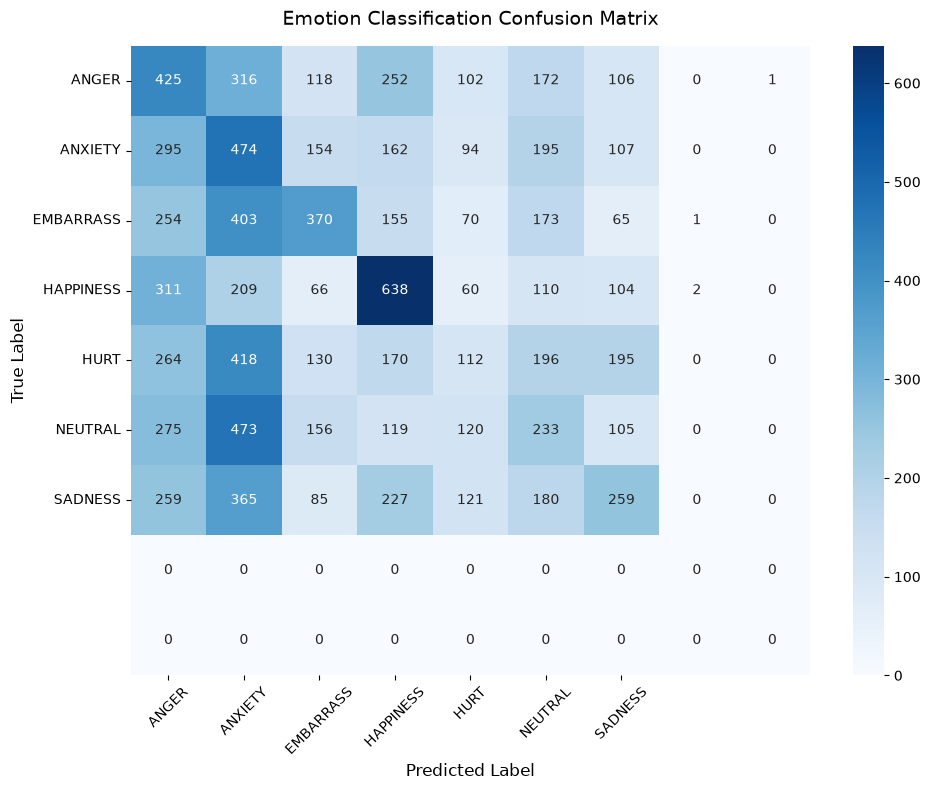

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 예시 클래스 이름 (감정 분류 모델 기준)
class_names = [
    "ANGER",
    "ANXIETY",
    "EMBARRASS",
    "HAPPINESS",
    "HURT",
    "NEUTRAL",
    "SADNESS",
]

# y_true: 실제 정답 레이블 배열/리스트, y_pred: 모델이 예측한 레이블 배열/리스트
# (실제 보유하신 실제값과 예측값 변수로 교체하여 사용하세요)
# 예: y_true = [...], y_pred = [...]

# 1. 혼동 행렬 계산
cm = confusion_matrix(y_true, y_pred)

# (선택) 비율(Normalize)로 보고 싶다면 아래 주석을 해제하세요 (행 기준 비율)
# cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 2. 시각화 세팅
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",  # 비율로 볼 경우 fmt='.2f'로 변경
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.title("Emotion Classification Confusion Matrix", fontsize=14, pad=15)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

# 3. 출력
plt.show()

전체 정확도는 24.08%<br>
테스트 데이터 규모: 총 10,426개의 샘플

총 7개의 감정을 분류하기에는 충분하지 않은 결과로 보인다.
훈련용 데이터의 경우, 약 14~15% 씩으로 충분히 고르게 들어가 있으나
HAPPINESE(기쁨)을 제외하고는 대부분이 ANXIETY(불안)으로 빠지는 형태로 훈련이 되어진 것으로 보인다.

HAPPINESS가 F1 = 0.42 (Recall: 0.55, Precision: 0.34)전체 감정 중 가장 높은 성능을 보이며, 특히 재현율이 0.55로 높아서, 실제로 '기쁨'인 데이터의 절반 이상을 찾아내지만 실제적으로 절반 이상이 다른 상태로 오 분류한다.

실제적으론 현재 수준에서는 쓸 수 없는 모델이다.

더 자세한 고찰은 Q4-2에서 이어서 진행하겠다.

Q4-2. 학습 과정에서 발생한 문제점(예: 과적합, 학습 지연 등)과 이를 해결하기 위해 시도한
방법(Learning Rate 조절, Dropout, Augmentation 등)을 작성하시오

1. 학습과정 중 발생한 문제점
    1. 찾은 데이터 셋의 용량이 큼
        
        - 7개의 감정별 데이터가 너무 많아서 다운 받을 수 없는 상황 외장 disk 를 써볼까 하다가 속도가 나오지 않아서 일부 데이터만 사용하기 함(Validation data만 사용)

        - 그럼에도 환경에 디스크 공간이 부족하여 압축된 파일 상태로 사용
            -> 파이썬의 zipfile 라이브러리가 있어 이를 이용하여 압축을 풀지 않은대로 사용

        - 압축 파일 마다 class 가 분리되어 있기 때문에 압축파일 탐색 시 압축파일 이름을 이용하여 class 를 재정의를 진행하고 zip 파일 내에 있는 이미지의 이름을 가지고 시작

        - 라벨 압축 파일이 있었으나, 당시에는 그렇게 생각못했으나 이전, labels.csv 와 있던 것과 같이 진행했으면 조금 더 수훨 했을 꺼 같음

    2. 손실 된 이미지

        - zip 파일로 된, 상태이기 때문에 파일의 상태를 몰랐으나 일부 깨져서 읽지 못하는 이미지가 존재함

        - 학습을 위해 돌아가던 중 실제 이미지를 꺼낼 때, 문제가 발생
        
        - 2가지의 처리를 진행
        
            - 처음 zip 파일에서 dataframe 을 만들때, 일일이 파일을 열어서 열리는지 확인하여 dataframe 을 만듦
                -> 초기 dataset 로딩이 느림
        
            - 실제 미니배치로 올리기 위해서 EmotionDataset 클래스에서 getitem 할때, 열리지 않는 이미지가 있다면, 까만 이미지로 미니 배치 크기를 유지하는 방향으로 진행함
            ![이슈](note_images/파일깨짐.png "이슈 이미지")

    3. 학습

        - 더 나은 방식을 찾기 위해, 
            -> 전체 훈련용 이미지의 장수를 1/10 줄이고 epoch를 늘려 훈련을 해보았으나, 정확률이 25% 안팎으로 실제 서비스에서 사용할만한 모델이 되지 않음.

            -> MobileNet을 전이학습하는 부분이기에 2가지로 분류기 층만 업데이트하는 방법과 전체를 미세 조절하는 방법 모두 사용했으나 경향은 비슷하게 나옴.

            -> 모델에서는 총 7가지의 감정을 분류하는 것으로 나타내였지만, 실제적으로 보이는 부분은 더 큰 분류인 긍정(Positive)과 부정(Negative) 그리고 중립(Neutral)으로 보는것이 더 나을 것으로 판단
            - Positive (긍정): HAPPINESS
            - Negative (부정): ANGER + ANXIETY + HURT + SADNESS
            - Neutral/Surprise: NEUTRAL + EMBARRASS

            추가 모델 학습
                조건:
                    - 샘플 1/10 (train, test) (1,785, 446)
                        - 시간상 결과를 볼 수 없어서 줄여서 진행
                    - 분류는 HAPPINESS(Positive), ANXIETY(Negative), NEUTRAL(Neutral)
                        - 결합하는 방식을 해보고 싶었으나, 용량의 한계로 이미지를 섞기 어려워서
                    - 분류 층만 수정
                    - epoch는 10회
                결과:
                    - 정확도 (24.08 % -> 47.98 %) 상승
                    - 정밀도, 재현율, F1-score
                    ![출력 결과](note_images/score.png "classification_report")
                    - Confusion Matrix
                    ![Confusion Matrix](note_images/confusionmatrix.png "Confusion Matrix")


2. 고찰
    1. 데이터 및 결과
        - 데이터의 신뢰도에 대한 문제
            - classes 의 분류 방법
                -> 전문가의 3명이 분류한 기준인데, 모두가 만장일치일지 모름
            - 데이터 개수를 충분히 사용 못함
                -> 50만개의 데이터가 있었지만, 테스트 pc의 한계로 사용하지 못함
        - 결과
            - 사용처
                사람의 서사 활동 중 표현받아야 할 감정은 학술적으로 많은 양의 감정보다는 확실하게 구분 될 수 있는 정도의 감정으로 요즘 표현에 어울리는 긍정/부정 에 맞는 정도로도 충분할 것으로 생각함
            - 훈련 디바이스의 한계로 많은 데이터를 사용하지 못하고, 제출기한을 맞추기 위하여 충분한 샘플을 재사용(Negative 로 재 분류된 이미지 샘플 섞기)하지 못하여 결과 적으로는 아쉬움
    2. 한계
        - 원본 트레이닝 데이터 50만장에 가까운 데이터를 받기 위해선 압축파일로 그대로 사용해도 890GB 에 달함
        - 실제 데이터 제공처에서 사용하는 모델(EmotionLab)과 했을 때의 정확도가 80% 정도가 나옴
        - 현재 과제에서는 사용되는 데이터 샘플 수가 5만 장 정도이며, 같은 모델을 사용하지 않았음
        - 또한 결과가 좋지 않은 것으로 실 사용하기에는 어려워 보임
    3. 제안
        - 앞서 감정이 3가지로 분류 했을 때의 정확도가 더 높았던 것으로 보이므로 이와 같은 방향으로 재 분류해서 테스트 해보면 더 나은 결과를 가져 올 것으로 보임
        - 현재는 이미지의 배경도 포함하고 있는데, 얼굴 부분만 또는 사람의 부분만 crop 된 샘플이면 더 나은 결과를 가져 올 것으로 생각 됨
        - 학습하고자 하는 부분이 서사 활동 중이며, 대상이 폰을 사용하고 있을 때를 가정한다면, 얼굴 정보만을 취득 해서 학습을 시켜야 하는 것으로 보임